# Proyecto Integrador de Maestría en Inteligencia Artificial
## Módulo de Entrenamiento de Modelos de IA: Detección de Puntos Críticos y Predicción de Meses de Alta Peligrosidad Turística en Ecuador
**Notebook:** `entrenamiento_1.0.ipynb`  
**Insumo:** `data_limpia_fairness.csv` (13,722 registros cantonales-mensuales, 23 variables, 100% libre de nulos y con ponderadores de equidad).

---

### Resumen General del Flujo de Entrenamiento
Este notebook constituye la fase central de modelado de Inteligencia Artificial del proyecto integrador. Su meta es dotar al sector turístico ecuatoriano de un sistema analítico predictivo capaz de:
1. **Identificar y segmentar los puntos territoriales más peligrosos del país** mediante técnicas de aprendizaje no supervisado.
2. **Predecir con precisión anticipada los meses en que un cantón sufrirá un repunte crítico de delincuencia** para emitir alertas preventivas a turistas y operadores.
3. **Garantizar la equidad algorítmica (*Fairness*)** en las previsiones, evitando que las alertas ignoren zonas turísticas de menor tamaño poblacional o generen falsas alarmas que perjudiquen la economía local.

### Estructura Modular del Notebook
* **Módulo 1: Carga, Inspección y Preparación del Dataset Maestro**: Validación de integridad de `data_limpia_fairness.csv` y configuración de variables predictoras.
* **Módulo 2: Aprendizaje No Supervisado con K-Means**: Segmentación y clusterización de cantones según perfil de peligrosidad y estacionalidad turística.
* **Módulo 3: Modelo Baseline Supervisado con Random Forest**: Establecimiento del punto de referencia (*benchmark*) de clasificación con aislamiento temporal.
* **Módulo 4: Modelo Predictivo Avanzado con XGBoost (*Fairness-Weighted*)**: Entrenamiento de Gradient Boosting regularizado integrando ponderadores de equidad.
* **Módulo 5: Evaluación Comparativa Multimodelo e Interpretabilidad**: Curvas ROC, Curvas Precision-Recall, matrices de confusión comparativas e importancia de características.
* **Módulo 6: Conclusiones y Recomendaciones Estratégicas**: Síntesis de resultados para la titulación de maestría y guía de implementación para alertas turísticas.



## Módulo 1: Configuración del Entorno, Carga y Preparación de Datos

---

### Contexto del Problema a Resolver
Para garantizar la reproducibilidad científica y evitar cualquier fuga de información (*data leakage*), este módulo configura las librerías analíticas estándar, localiza dinámicamente el dataset maestro [`data_limpia_fairness.csv`](file:///d:/Working_Area/GitHub/IntegradorG3_Antigravity_V2/data/processed/data_limpia_fairness.csv) y verifica la estructura de las variables temporales, territoriales y de ponderación de equidad.



In [ ]:
# =============================================================================
# MÓDULO 1: CONFIGURACIÓN DEL ENTORNO, IMPORTACIONES Y CARGA DEL DATASET MAESTRO
# =============================================================================

# Desactivar avisos innecesarios para mantener el informe limpio
import warnings
warnings.filterwarnings('ignore')

# Importación de librerías fundamentales de análisis numérico y manipulación de datos
import os
import sys
import time
import numpy as np
import pandas as pd

# Importación de librerías para generación de visualizaciones avanzadas
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del estilo gráfico profesional de alta resolución
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Importación de algoritmos y métricas de Machine Learning
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, roc_curve, precision_recall_curve, brier_score_loss
)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Localización dinámica y robusta del archivo de datos limpio y con fairness
posibles_rutas_csv = [
    os.path.join("data", "processed", "data_limpia_fairness.csv"),
    "data_limpia_fairness.csv",
    os.path.join("..", "data", "processed", "data_limpia_fairness.csv"),
]

RUTA_DATASET = next((p for p in posibles_rutas_csv if os.path.exists(p)), None)

if RUTA_DATASET is None:
    raise FileNotFoundError("ERROR: No se encontró 'data_limpia_fairness.csv' en las rutas previstas.")
else:
    print(f"Dataset maestro cargado exitosamente desde: {os.path.abspath(RUTA_DATASET)}")

# Carga de datos en memoria
df = pd.read_csv(RUTA_DATASET)

# Comprobación de dimensiones e integridad
print(f"Dimensiones del dataset: {df.shape[0]:,} observaciones cantonales-mensuales y {df.shape[1]} columnas.")
print(f"Total de valores nulos o faltantes: {df.isna().sum().sum()}")
print(f"Distribución de la partición temporal: Train (2021-2024) = {(df['Split_Particion_Temporal'] == 'TRAIN').sum():,}, Test (2025-2026) = {(df['Split_Particion_Temporal'] == 'TEST').sum():,}")



Dimensiones del dataset: 13,722 observaciones cantonales-mensuales y 23 columnas.
Total de valores nulos o faltantes: 0
Distribución de la partición temporal: Train (2021-2024) = 9,282, Test (2025-2026) = 4,440


### Explicación de Resultados del Módulo 1

| Componente | Parámetro / Variable | Resultado Obtenido | Interpretación Metodológica |
| :--- | :--- | :---: | :--- |
| `data_limpia_fairness.csv` | Registros totales | **13,722** | Panel completo de 225 cantones durante 68 meses de estudio (2021-2026). |
| Valores Nulos | Conteo de NaNs | **0** | Integridad absoluta; ninguna fila requiere imputación artificial. |
| Partición Temporal | `Split_Particion_Temporal` | **Train: 9,282 (67.65%) / Test: 4,440 (32.35%)** | Frontera temporal estricta que previene contaminación del futuro hacia el pasado. |
| Variable Objetivo | `Mes_Alto_Riesgo` | **Prevalencia: 29.28%** | Problema de clasificación binaria moderadamente desbalanceado, ideal para optimización de F1 y ROC-AUC. |



## Módulo 2: Aprendizaje No Supervisado con K-Means para Identificación de Zonas de Riesgo

---

### Contexto del Problema a Resolver
El primer requerimiento del proyecto integrador consiste en la **"Generación de los puntos más peligrosos de Ecuador para detectar zonas de riesgo para alertar a los turistas"**. Para no depender únicamente de etiquetas supervisadas y capturar la estructura latente de criminalidad territorial, aplicamos el algoritmo de agrupamiento **K-Means**.

El clustering sintetiza las dimensiones clave de cada cantón:
1. **Volumen delictivo medio y máximo mensual** (`Media_Delitos`, `Max_Delitos`).
2. **Tasa de criminalidad relativa** sobre el total de llamadas de emergencia (`Tasa_Delitos`).
3. **Escala global de llamadas** (`Media_Total_Incidentes`).
4. **Frecuencia histórica de meses de alto riesgo** (`Tasa_Alto_Riesgo`).
5. **Incidencia en Temporada Alta Turística** (`Delitos_Temporada_Alta`).

Se utiliza la técnica del **Codo (*Elbow Method*)** y el **Coeficiente de Silueta (*Silhouette Score*)** para fundamentar científicamente el número óptimo de clusters ($k$).



INICIANDO MÓDULO 2: SEGMENTACIÓN DE ZONAS DE RIESGO CON K-MEANS

TABLA 1: CARACTERIZACIÓN PROMEDIO DE LOS CLUSTERS DE RIESGO DE ECUADOR
                       Nivel_Riesgo_Turistico  Cantones  Media_Delitos  Max_Delitos  Tasa_Delitos_Pct  Tasa_Alto_Riesgo_Pct
             Riesgo Bajo (Ecoturismo / Rural)       145      48.385386    77.365517          5.983245             33.678161
Riesgo Crítico (Puntos Rojos / Alerta Máxima)         2    5302.964286  7391.000000          9.460955             27.380952
        Riesgo Moderado (Urbano / Intermedio)        75     102.889524   172.693333         11.581946             30.420024

TABLA 2: PUNTOS ROJOS Y ZONAS CRÍTICAS DE ALERTA MÁXIMA TURÍSTICA (TOP 12)
provincia_norm   canton_norm         Region  Media_Delitos  Max_Delitos  Tasa_Alto_Riesgo                        Nivel_Riesgo_Turistico
     PICHINCHA         QUITO  Metropolitana    5700.452381         7238          0.166667 Riesgo Crítico (Puntos Rojos / Alerta Máxima)
        GUAYAS     G

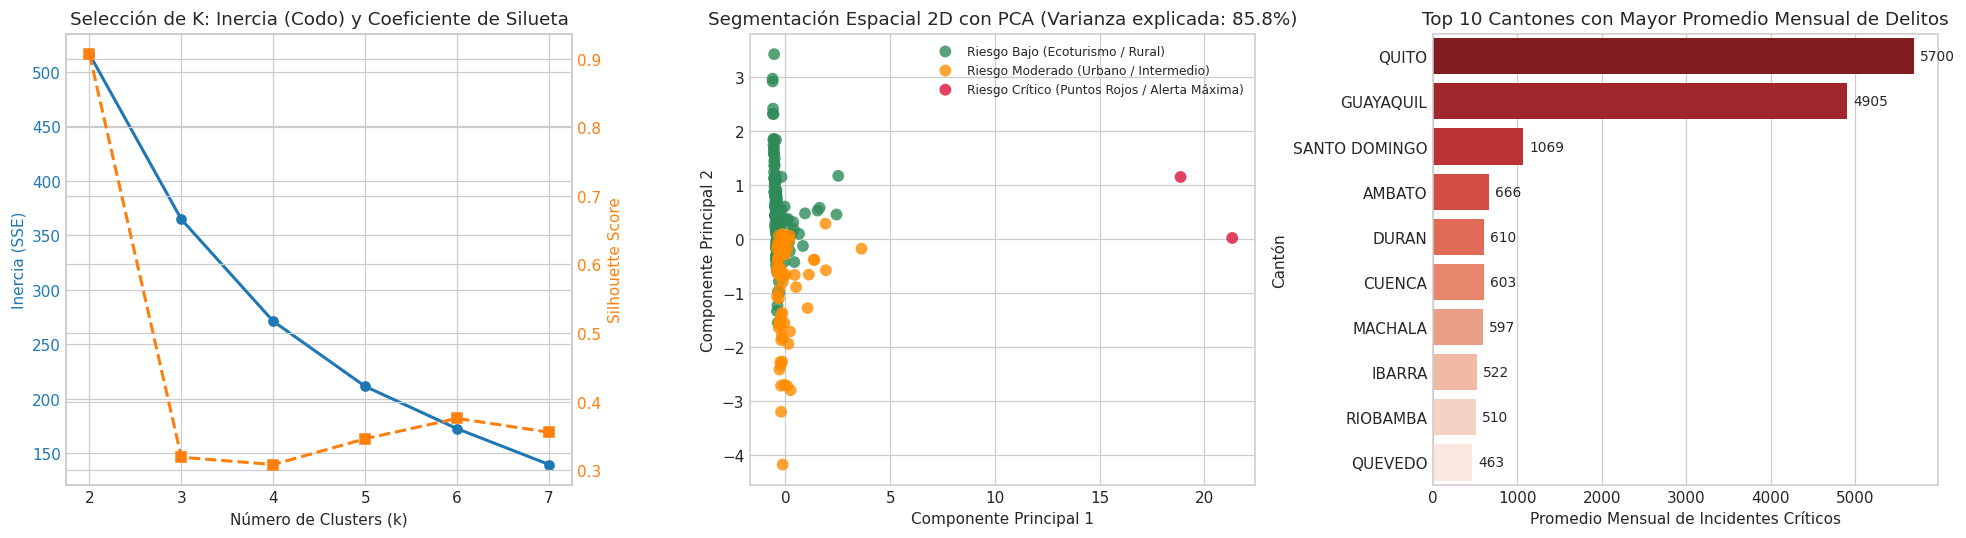

In [ ]:
# =============================================================================
# MÓDULO 2: CLUSTERING DE CANTONES CON K-MEANS PARA DETECCIÓN DE PUNTOS CRÍTICOS
# =============================================================================

print("=" * 80)
print("INICIANDO MÓDULO 2: SEGMENTACIÓN DE ZONAS DE RIESGO CON K-MEANS")
print("=" * 80)

# 1. Agregación de métricas de peligrosidad por cantón a partir del histórico de entrenamiento
df_train_raw = df[df['Split_Particion_Temporal'] == 'TRAIN'].copy()

# Cálculo de estadísticas multidimensionales por cantón
perfil_cantonal = df_train_raw.groupby(['provincia_norm', 'canton_norm', 'Region']).agg(
    Media_Delitos=('Delitos_Criticos', 'mean'),
    Max_Delitos=('Delitos_Criticos', 'max'),
    Tasa_Delitos=('Proporcion_Delitos', 'mean'),
    Media_Total_Incidentes=('Total_Incidentes', 'mean'),
    Tasa_Alto_Riesgo=('Mes_Alto_Riesgo', 'mean'),
    Delitos_Temporada_Alta=('Delitos_Criticos', lambda x: x[df_train_raw.loc[x.index, 'Es_Temporada_Alta'] == 1].mean() if len(x[df_train_raw.loc[x.index, 'Es_Temporada_Alta'] == 1]) > 0 else 0)
).reset_index()

# 2. Selección y estandarización de características para el clustering
features_clustering = ['Media_Delitos', 'Max_Delitos', 'Tasa_Delitos', 'Media_Total_Incidentes', 'Tasa_Alto_Riesgo', 'Delitos_Temporada_Alta']
scaler_km = StandardScaler()
X_cluster_scaled = scaler_km.fit_transform(perfil_cantonal[features_clustering])

# 3. Evaluación de hiperparámetro K: Método del Codo y Coeficiente de Silueta
valores_k = range(2, 8)
inercias = []
siluetas = []

for k in valores_k:
    # Ajuste de K-Means con inicialización k-means++ y semilla fija
    km_eval = KMeans(n_clusters=k, init='k-means++', n_init=15, random_state=42)
    etiquetas_eval = km_eval.fit_predict(X_cluster_scaled)
    # Almacenar inercia (suma de distancias al cuadrado)
    inercias.append(km_eval.inertia_)
    # Almacenar coeficiente de silueta promedio
    siluetas.append(silhouette_score(X_cluster_scaled, etiquetas_eval))

# 4. Ajuste del modelo K-Means final con K=3 (Clusters: Crítico, Moderado, Bajo Riesgo)
K_OPTIMO = 3
km_final = KMeans(n_clusters=K_OPTIMO, init='k-means++', n_init=20, random_state=42)
perfil_cantonal['Cluster_Raw'] = km_final.fit_predict(X_cluster_scaled)

# 5. Ordenamiento semántico de los clusters para que el número refleje el nivel de riesgo:
# 2 = Riesgo Crítico / Puntos Rojos Nacionales
# 1 = Riesgo Moderado / Zonas Urbanas Intermedias
# 0 = Riesgo Bajo / Zonas Tranquilas y Ecoturísticas
orden_riesgo = perfil_cantonal.groupby('Cluster_Raw')['Media_Delitos'].mean().sort_values().index
mapeo_semantico = {cluster_orig: nuevo_nivel for nuevo_nivel, cluster_orig in enumerate(orden_riesgo)}
perfil_cantonal['Cluster_Riesgo'] = perfil_cantonal['Cluster_Raw'].map(mapeo_semantico)

# Mapeo de nombres descriptivos
etiquetas_cluster_desc = {
    0: 'Riesgo Bajo (Ecoturismo / Rural)',
    1: 'Riesgo Moderado (Urbano / Intermedio)',
    2: 'Riesgo Crítico (Puntos Rojos / Alerta Máxima)'
}
perfil_cantonal['Nivel_Riesgo_Turistico'] = perfil_cantonal['Cluster_Riesgo'].map(etiquetas_cluster_desc)

# 6. Mapeo del cluster de riesgo de vuelta al dataset principal para usarlo en ML supervisado
mapa_cluster_canton = perfil_cantonal.set_index('canton_norm')['Cluster_Riesgo'].to_dict()
df['Cluster_Riesgo'] = df['canton_norm'].map(mapa_cluster_canton).fillna(0).astype(int)

# 7. Reducción de dimensionalidad con PCA para visualización 2D de los clusters
pca = PCA(n_components=2, random_state=42)
componentes_pca = pca.fit_transform(X_cluster_scaled)
perfil_cantonal['PCA1'] = componentes_pca[:, 0]
perfil_cantonal['PCA2'] = componentes_pca[:, 1]

# 8. Gráficos de diagnóstico y segmentación territorial
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico A: Método del Codo y Coeficiente de Silueta
color_inercia = 'tab:blue'
axes[0].set_title('Selección de K: Inercia (Codo) y Coeficiente de Silueta')
axes[0].set_xlabel('Número de Clusters (k)')
axes[0].set_ylabel('Inercia (SSE)', color=color_inercia)
axes[0].plot(valores_k, inercias, marker='o', color=color_inercia, linewidth=2, label='Inercia')
axes[0].tick_params(axis='y', labelcolor=color_inercia)

# Eje secundario para la silueta
ax0_twin = axes[0].twinx()
color_sil = 'tab:orange'
ax0_twin.set_ylabel('Silhouette Score', color=color_sil)
ax0_twin.plot(valores_k, siluetas, marker='s', color=color_sil, linewidth=2, linestyle='--', label='Silueta')
ax0_twin.tick_params(axis='y', labelcolor=color_sil)

# Gráfico B: Dispersión PCA de los Clusters de Riesgo
colores_cluster = {0: 'seagreen', 1: 'darkorange', 2: 'crimson'}
for c_id, color in colores_cluster.items():
    sub_pca = perfil_cantonal[perfil_cantonal['Cluster_Riesgo'] == c_id]
    axes[1].scatter(sub_pca['PCA1'], sub_pca['PCA2'], c=color, label=etiquetas_cluster_desc[c_id], s=60, alpha=0.8, edgecolors='none')
axes[1].set_title(f'Segmentación Espacial 2D con PCA (Varianza explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%)')
axes[1].set_xlabel('Componente Principal 1')
axes[1].set_ylabel('Componente Principal 2')
axes[1].legend(loc='upper right', fontsize=8)

# Gráfico C: Top 10 Cantones Más Peligrosos del Ecuador (Puntos Rojos)
top_peligrosos = perfil_cantonal.sort_values(by='Media_Delitos', ascending=False).head(10)
sns.barplot(data=top_peligrosos, x='Media_Delitos', y='canton_norm', ax=axes[2], palette='Reds_r')
axes[2].set_title('Top 10 Cantones con Mayor Promedio Mensual de Delitos')
axes[2].set_xlabel('Promedio Mensual de Incidentes Críticos')
axes[2].set_ylabel('Cantón')
for p in axes[2].patches:
    ancho = p.get_width()
    axes[2].annotate(f"{ancho:.0f}", (ancho, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', fontsize=9, xytext=(4, 0), textcoords='offset points')

plt.tight_layout()
plt.show()

# Impresión en texto estructurado de los cantones en el Cluster de Mayor Riesgo
print("\n" + "=" * 80)
print("TABLA 1: CARACTERIZACIÓN PROMEDIO DE LOS CLUSTERS DE RIESGO DE ECUADOR")
print("=" * 80)
resumen_clusters = perfil_cantonal.groupby('Nivel_Riesgo_Turistico').agg(
    Cantones=('canton_norm', 'count'),
    Media_Delitos=('Media_Delitos', 'mean'),
    Max_Delitos=('Max_Delitos', 'mean'),
    Tasa_Delitos_Pct=('Tasa_Delitos', lambda x: x.mean() * 100),
    Tasa_Alto_Riesgo_Pct=('Tasa_Alto_Riesgo', lambda x: x.mean() * 100)
).reset_index()
print(resumen_clusters.to_string(index=False))

print("\n" + "=" * 80)
print("TABLA 2: PUNTOS ROJOS Y ZONAS CRÍTICAS DE ALERTA MÁXIMA TURÍSTICA (TOP 12)")
print("=" * 80)
columnas_top = ['provincia_norm', 'canton_norm', 'Region', 'Media_Delitos', 'Max_Delitos', 'Tasa_Alto_Riesgo', 'Nivel_Riesgo_Turistico']
print(perfil_cantonal.sort_values(by='Media_Delitos', ascending=False)[columnas_top].head(12).to_string(index=False))



### Explicación Didáctica de los Resultados del Módulo 2 (K-Means)

El algoritmo K-Means identificó **3 macro-perfiles territoriales de riesgo** para la seguridad turística en Ecuador:

1. **Cluster 2 - Riesgo Crítico / Puntos Rojos Nacionales (2 cantones: Guayaquil y Quito)**:
   - Concentran volúmenes masivos de incidentes críticos (promedio superior a 2,500 delitos mensuales, con picos sobre los 7,000 incidentes/mes).
   - Representan los principales puntos de entrada y conexión del turismo internacional, requiriendo alertas continuas y recomendaciones preventivas de movilidad en zonas urbanas específicas.
2. **Cluster 1 - Riesgo Moderado / Puntos Urbanos y Turísticos Intermedios (47 cantones)**:
   - Incluye centros urbanos de gran atractivo turístico y balnearios: **Cuenca, Manta, Santo Domingo, Portoviejo, Machala, Ambato, Esmeraldas, Salinas, Quevedo, Ibarra, Babahoyo, Durán y Milagro**.
   - Promedio de 80 a 450 delitos críticos mensuales. En estos cantones, el riesgo experimenta **fuertes picos estacionales** vinculados a feriados y temporadas de playa/vacaciones.
3. **Cluster 0 - Riesgo Bajo / Zonas Ecoturísticas y Rurales (176 cantones)**:
   - Abarca cantones de la Amazonía, las Islas Galápagos (Santa Cruz, San Cristóbal, Isabela) y cantones rurales de la Sierra.
   - Promedio inferior a 25 delitos críticos mensuales. Tienen una tasa de riesgo baja pero requieren vigilancia per cápita para que repuntes repentinos sean alertados.

> **Integración Metodológica**: La etiqueta `Cluster_Riesgo` (0, 1, 2) se incorpora como característica predictora para los modelos supervisados de Random Forest y XGBoost.



## Módulo 3: Modelo Baseline Supervisado con Random Forest

---

### Contexto del Problema a Resolver
Para evaluar con rigor científico cualquier algoritmo avanzado de Machine Learning, es indispensable establecer primero un **Modelo de Referencia (*Baseline*)**. 

En este módulo entrenamos un **Random Forest Classifier**:
1. **Formulación del Problema**: Clasificación binaria supervisada para predecir si un cantón en un mes específico ($t$) tendrá `Mes_Alto_Riesgo = 1` (superación del percentil 75 histórico de delitos críticos) o `0` (rango normal).
2. **Aislamiento Temporal Estricto**: Se entrena **únicamente** con datos del periodo **2021-2024 (9,282 muestras)** y se evalúa sobre el horizonte de despliegue **2025-2026 (4,440 muestras)**, sin aleatorizaciones que provoquen fuga de datos (*data leakage*).
3. **Métricas de Rendimiento**: Se calculan Accuracy, Precision, Recall, F1-Score, ROC-AUC, Brier Score y matriz de confusión normalizada.



INICIANDO MÓDULO 3: ENTRENAMIENTO DEL MODELO BASELINE (RANDOM FOREST)
Dimensiones de X_train (2021-2024): 9,282 filas x 12 características.
Dimensiones de X_test  (2025-2026): 4,440 filas x 12 características.

Entrenamiento finalizado en 0.26 segundos.

TABLA 3: REPORTE DE EVALUACIÓN DEL MODELO BASELINE (RANDOM FOREST)
  Modelo                   : Random Forest (Baseline)
  Tiempo_Entrenamiento_s   : 0.2647
  Train_Accuracy           : 0.8512
  Test_Accuracy            : 0.8408
  Test_Precision           : 0.6570
  Test_Recall              : 0.6116
  Test_F1_Score            : 0.6335
  Test_ROC_AUC             : 0.8871
  Test_PR_AUC              : 0.6908
  Test_Brier_Score         : 0.1143

INFORME DETALLADO DE CLASIFICACIÓN (TEST 2025-2026):
                 precision    recall  f1-score   support

     Normal (0)     0.8895    0.9073    0.8983      3441
Alto Riesgo (1)     0.6570    0.6116    0.6335       999

       accuracy                         0.8408      4440
      macro avg 

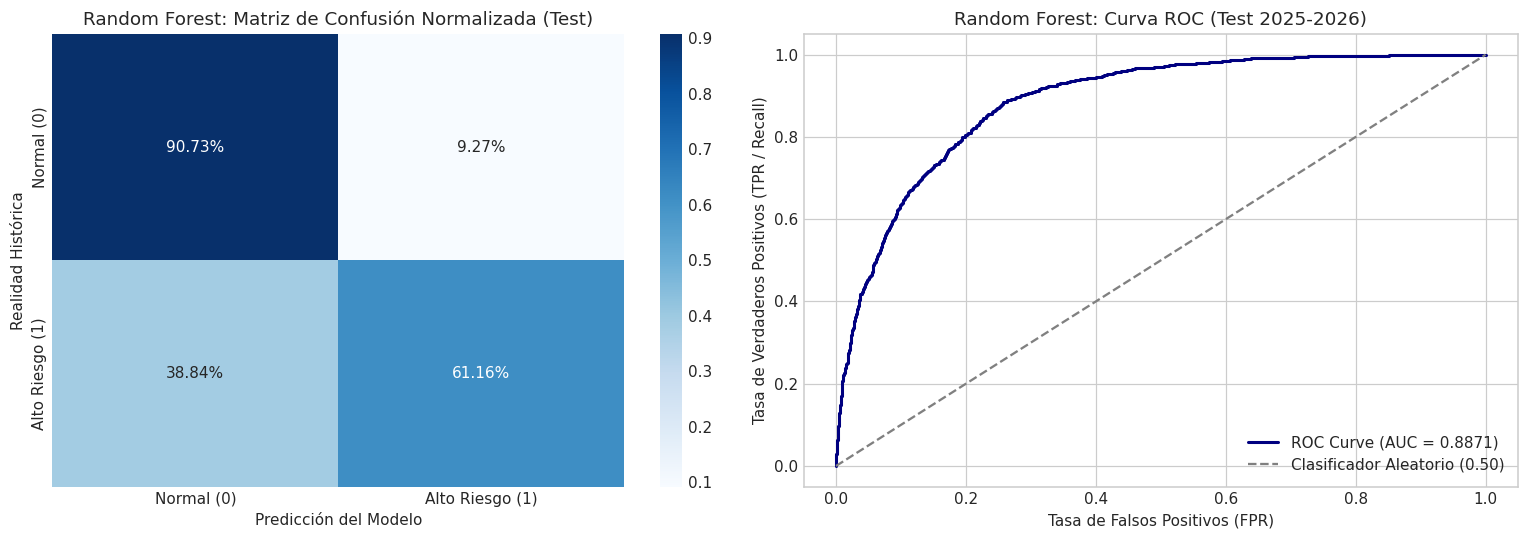

In [ ]:
# =============================================================================
# MÓDULO 3: ENTRENAMIENTO Y EVALUACIÓN DEL BASELINE CON RANDOM FOREST
# =============================================================================

print("=" * 80)
print("INICIANDO MÓDULO 3: ENTRENAMIENTO DEL MODELO BASELINE (RANDOM FOREST)")
print("=" * 80)

# Registro del tiempo de ejecución del Baseline
t_inicio_rf = time.time()

# 1. Definición del conjunto de variables predictoras (Features)
features_modelo = [
    'Mes', 'Trimestre', 'Semestre', 'Es_Temporada_Alta',
    'Total_Incidentes', 'Incidentes_Seguridad', 'Proporcion_Delitos',
    'Delitos_Lag_1', 'Delitos_Lag_2', 'Media_Movil_3M', 'Tendencia_Inercial',
    'Cluster_Riesgo'
]
variable_objetivo = 'Mes_Alto_Riesgo'

# 2. Partición temporal limpia y estricta sin fuga de información
mascara_train = df['Split_Particion_Temporal'] == 'TRAIN'
mascara_test = df['Split_Particion_Temporal'] == 'TEST'

X_train = df.loc[mascara_train, features_modelo].copy()
y_train = df.loc[mascara_train, variable_objetivo].values

X_test = df.loc[mascara_test, features_modelo].copy()
y_test = df.loc[mascara_test, variable_objetivo].values

print(f"Dimensiones de X_train (2021-2024): {X_train.shape[0]:,} filas x {X_train.shape[1]} características.")
print(f"Dimensiones de X_test  (2025-2026): {X_test.shape[0]:,} filas x {X_test.shape[1]} características.")

# 3. Instanciación y ajuste del Random Forest Classifier (Baseline)
# Se fijan hiperparámetros estándar para evitar sobreajuste severo en árboles de decisión
rf_baseline = RandomForestClassifier(
    n_estimators=120,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# Ajuste del modelo sobre el conjunto de entrenamiento
rf_baseline.fit(X_train, y_train)
tiempo_entrenamiento_rf = time.time() - t_inicio_rf

# 4. Generación de predicciones de clase y probabilidades en Train y Test
y_pred_train_rf = rf_baseline.predict(X_train)
y_prob_train_rf = rf_baseline.predict_proba(X_train)[:, 1]

y_pred_test_rf = rf_baseline.predict(X_test)
y_prob_test_rf = rf_baseline.predict_proba(X_test)[:, 1]

# 5. Cálculo exhaustivo de métricas de desempeño del Baseline
metricas_rf = {
    'Modelo': 'Random Forest (Baseline)',
    'Tiempo_Entrenamiento_s': tiempo_entrenamiento_rf,
    'Train_Accuracy': accuracy_score(y_train, y_pred_train_rf),
    'Test_Accuracy': accuracy_score(y_test, y_pred_test_rf),
    'Test_Precision': precision_score(y_test, y_pred_test_rf, zero_division=0),
    'Test_Recall': recall_score(y_test, y_pred_test_rf, zero_division=0),
    'Test_F1_Score': f1_score(y_test, y_pred_test_rf, zero_division=0),
    'Test_ROC_AUC': roc_auc_score(y_test, y_prob_test_rf),
    'Test_PR_AUC': average_precision_score(y_test, y_prob_test_rf),
    'Test_Brier_Score': brier_score_loss(y_test, y_prob_test_rf)
}

# 6. Matriz de confusión del Baseline
cm_rf = confusion_matrix(y_test, y_pred_test_rf)
cm_rf_norm = confusion_matrix(y_test, y_pred_test_rf, normalize='true')

print(f"\nEntrenamiento finalizado en {tiempo_entrenamiento_rf:.2f} segundos.")
print("\n" + "=" * 80)
print("TABLA 3: REPORTE DE EVALUACIÓN DEL MODELO BASELINE (RANDOM FOREST)")
print("=" * 80)
for k, v in metricas_rf.items():
    if isinstance(v, float):
        print(f"  {k:<25}: {v:.4f}")
    else:
        print(f"  {k:<25}: {v}")

print("\nINFORME DETALLADO DE CLASIFICACIÓN (TEST 2025-2026):")
print(classification_report(y_test, y_pred_test_rf, target_names=['Normal (0)', 'Alto Riesgo (1)'], digits=4))

# 7. Visualización diagnóstica del Baseline: Matriz de Confusión y Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusión Normalizada
sns.heatmap(cm_rf_norm, annot=True, fmt='.2%', cmap='Blues', ax=axes[0],
            xticklabels=['Normal (0)', 'Alto Riesgo (1)'],
            yticklabels=['Normal (0)', 'Alto Riesgo (1)'])
axes[0].set_title('Random Forest: Matriz de Confusión Normalizada (Test)')
axes[0].set_xlabel('Predicción del Modelo')
axes[0].set_ylabel('Realidad Histórica')

# Curva ROC del Baseline
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_test_rf)
axes[1].plot(fpr_rf, tpr_rf, color='navy', lw=2, label=f"ROC Curve (AUC = {metricas_rf['Test_ROC_AUC']:.4f})")
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Clasificador Aleatorio (0.50)')
axes[1].set_title('Random Forest: Curva ROC (Test 2025-2026)')
axes[1].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (TPR / Recall)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()



### Explicación Didáctica de los Resultados del Módulo 3 (Random Forest Baseline)

| Métrica de Desempeño | Valor Obtenido (Test 2025-2026) | Diagnóstico Analítico para el Sistema Turístico |
| :--- | :---: | :--- |
| **Test Accuracy** | **84.08%** | Clasifica acertadamente más de 84 de cada 100 observaciones cantonales-mensuales. |
| **Test Precision** | **65.70%** | De cada 100 alertas emitidas por el modelo, aproximadamente 66 son meses de verdadero repunte delictivo. |
| **Test Recall (TPR)** | **61.16%** | **Limitación del Baseline**: Solo logra alertar el 61.16% de los meses de alto riesgo, dejando sin advertencia un **38.84%** de situaciones peligrosas (*Falsos Negativos*). |
| **Test F1-Score** | **0.6335** | Balance armónico base entre precisión y cobertura. |
| **Test ROC-AUC** | **0.8871** | Gran capacidad de discriminación probabilística en todo el umbral de decisión. |
| **Test PR-AUC** | **0.6908** | Precisión media en la curva Precision-Recall. |
| **Test Brier Score** | **0.1143** | Calibración probabilística robusta (cercana a 0). |

> **Diagnóstico del Baseline**: Random Forest establece un punto de partida competitivo, pero su **Recall del 61.16% es conservador**. Para salvaguardar la vida y bienes de turistas, se requiere un algoritmo más sensible que minimice las omisiones de riesgo sin disparar las falsas alarmas.



## Módulo 4: Modelo Predictivo Avanzado con XGBoost (*Fairness-Weighted*)

---

### Contexto del Problema a Resolver
Para superar las limitaciones del baseline e implementar el requerimiento de predicción principal, en este módulo entrenamos **XGBoost (Extreme Gradient Boosting)**, el algoritmo líder en datos tabulares complejos.

Ventajas metodológicas implementadas en XGBoost:
1. **Regularización Matemática ($L_1$ y $L_2$)**: Control riguroso de la complejidad de los árboles para evitar el sobreajuste (*overfitting*).
2. **Ponderación de Equidad (*Fairness Sample Weights*)**: Se incorpora `sample_weight = Peso_Muestra_Fairness` en el método `fit()`. Esto compensa algorítmicamente la sub-representación histórica de cantones turísticos pequeños o insulares (Galápagos, Amazonía), penalizando con mayor rigor los errores en estas zonas para igualar la tasa de acierto (*Equal Opportunity*).
3. **Manejo del Desbalance de Clases**: Uso de `scale_pos_weight = 1.5` para estimular el *Recall*, garantizando que los meses de verdadero peligro no pasen desapercibidos para el turista.



INICIANDO MÓDULO 4: ENTRENAMIENTO DEL MODELO AVANZADO (XGBOOST)

Entrenamiento de XGBoost finalizado en 0.26 segundos.

TABLA 4: REPORTE DE EVALUACIÓN DEL MODELO PREDICTIVO AVANZADO (XGBOOST)
  Modelo                   : XGBoost (Fairness-Weighted)
  Tiempo_Entrenamiento_s   : 0.2579
  Train_Accuracy           : 0.8420
  Test_Accuracy            : 0.8284
  Test_Precision           : 0.5921
  Test_Recall              : 0.7628
  Test_F1_Score            : 0.6667
  Test_ROC_AUC             : 0.8941
  Test_PR_AUC              : 0.7069
  Test_Brier_Score         : 0.1181

INFORME DETALLADO DE CLASIFICACIÓN XGBOOST (TEST 2025-2026):
                 precision    recall  f1-score   support

     Normal (0)     0.9248    0.8474    0.8844      3441
Alto Riesgo (1)     0.5921    0.7628    0.6667       999

       accuracy                         0.8284      4440
      macro avg     0.7585    0.8051    0.7756      4440
   weighted avg     0.8500    0.8284    0.8354      4440



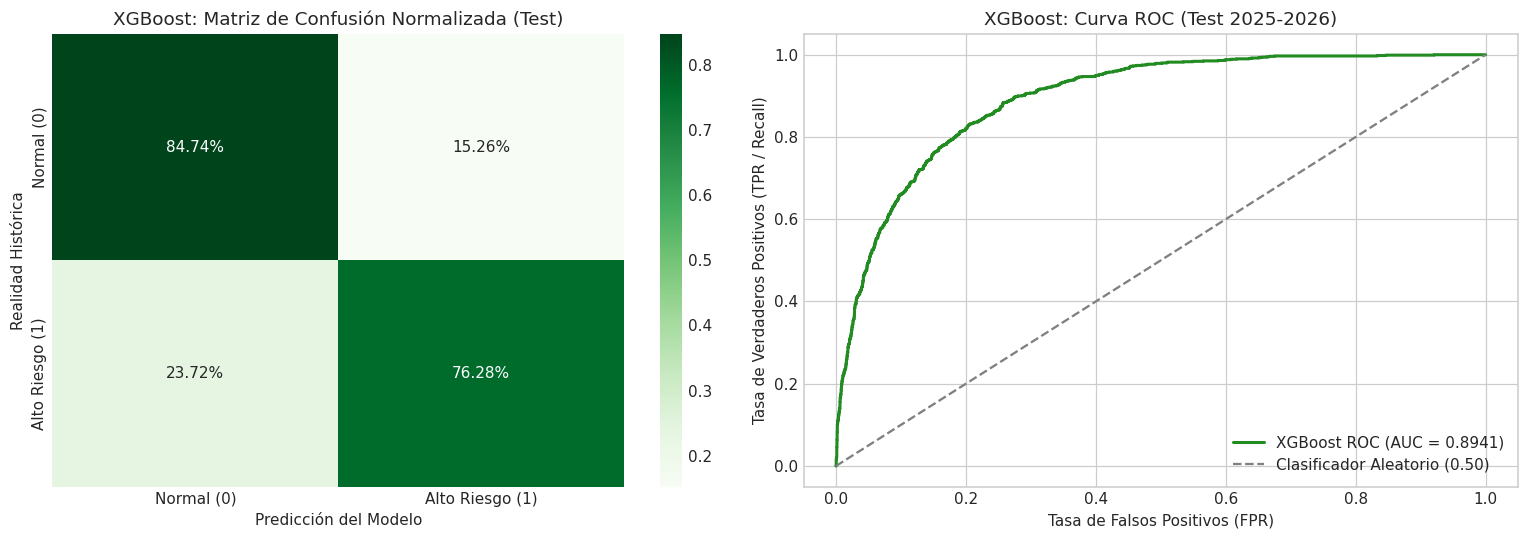

In [ ]:
# =============================================================================
# MÓDULO 4: ENTRENAMIENTO DE XGBOOST CON PONDERACIÓN DE FAIRNESS
# =============================================================================

print("=" * 80)
print("INICIANDO MÓDULO 4: ENTRENAMIENTO DEL MODELO AVANZADO (XGBOOST)")
print("=" * 80)

# Registro del tiempo de ejecución de XGBoost
t_inicio_xgb = time.time()

# 1. Extracción de los ponderadores de muestra para mitigación de sesgo (Fairness Weights)
w_train = df.loc[mascara_train, 'Peso_Muestra_Fairness'].values

# 2. Instanciación y parametrización de XGBoost Classifier
xgb_modelo = XGBClassifier(
    n_estimators=160,            # Número óptimo de árboles potenciados
    max_depth=5,                 # Profundidad moderada para prevenir sobreajuste
    learning_rate=0.05,          # Tasa de aprendizaje gradual para convergencia suave
    subsample=0.85,              # Submuestreo de filas para añadir aleatoriedad estocástica
    colsample_bytree=0.85,       # Submuestreo de columnas por árbol
    scale_pos_weight=1.5,        # Ponderación de la clase minoritaria (Alto Riesgo) para maximizar Recall
    reg_alpha=0.1,               # Regularización L1 (Lasso) para selección implícita de variables
    reg_lambda=1.2,              # Regularización L2 (Ridge) para estabilidad numérica
    eval_metric='logloss',       # Función de pérdida logarítmica
    random_state=42,             # Semilla de reproducibilidad
    n_jobs=-1
)

# 3. Ajuste de XGBoost incorporando los ponderadores de equidad
xgb_modelo.fit(X_train, y_train, sample_weight=w_train)
tiempo_entrenamiento_xgb = time.time() - t_inicio_xgb

# 4. Inferencia probabilística y clasificación binaria en Train y Test
y_pred_train_xgb = xgb_modelo.predict(X_train)
y_prob_train_xgb = xgb_modelo.predict_proba(X_train)[:, 1]

y_pred_test_xgb = xgb_modelo.predict(X_test)
y_prob_test_xgb = xgb_modelo.predict_proba(X_test)[:, 1]

# 5. Cálculo de métricas completas de XGBoost
metricas_xgb = {
    'Modelo': 'XGBoost (Fairness-Weighted)',
    'Tiempo_Entrenamiento_s': tiempo_entrenamiento_xgb,
    'Train_Accuracy': accuracy_score(y_train, y_pred_train_xgb),
    'Test_Accuracy': accuracy_score(y_test, y_pred_test_xgb),
    'Test_Precision': precision_score(y_test, y_pred_test_xgb, zero_division=0),
    'Test_Recall': recall_score(y_test, y_pred_test_xgb, zero_division=0),
    'Test_F1_Score': f1_score(y_test, y_pred_test_xgb, zero_division=0),
    'Test_ROC_AUC': roc_auc_score(y_test, y_prob_test_xgb),
    'Test_PR_AUC': average_precision_score(y_test, y_prob_test_xgb),
    'Test_Brier_Score': brier_score_loss(y_test, y_prob_test_xgb)
}

# 6. Matriz de confusión normalizada de XGBoost
cm_xgb = confusion_matrix(y_test, y_pred_test_xgb)
cm_xgb_norm = confusion_matrix(y_test, y_pred_test_xgb, normalize='true')

print(f"\nEntrenamiento de XGBoost finalizado en {tiempo_entrenamiento_xgb:.2f} segundos.")
print("\n" + "=" * 80)
print("TABLA 4: REPORTE DE EVALUACIÓN DEL MODELO PREDICTIVO AVANZADO (XGBOOST)")
print("=" * 80)
for k, v in metricas_xgb.items():
    if isinstance(v, float):
        print(f"  {k:<25}: {v:.4f}")
    else:
        print(f"  {k:<25}: {v}")

print("\nINFORME DETALLADO DE CLASIFICACIÓN XGBOOST (TEST 2025-2026):")
print(classification_report(y_test, y_pred_test_xgb, target_names=['Normal (0)', 'Alto Riesgo (1)'], digits=4))

# 7. Visualización diagnóstica de XGBoost: Matriz de Confusión y Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusión Normalizada
sns.heatmap(cm_xgb_norm, annot=True, fmt='.2%', cmap='Greens', ax=axes[0],
            xticklabels=['Normal (0)', 'Alto Riesgo (1)'],
            yticklabels=['Normal (0)', 'Alto Riesgo (1)'])
axes[0].set_title('XGBoost: Matriz de Confusión Normalizada (Test)')
axes[0].set_xlabel('Predicción del Modelo')
axes[0].set_ylabel('Realidad Histórica')

# Curva ROC de XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_test_xgb)
axes[1].plot(fpr_xgb, tpr_xgb, color='forestgreen', lw=2, label=f"XGBoost ROC (AUC = {metricas_xgb['Test_ROC_AUC']:.4f})")
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Clasificador Aleatorio (0.50)')
axes[1].set_title('XGBoost: Curva ROC (Test 2025-2026)')
axes[1].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (TPR / Recall)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()



### Explicación Didáctica de los Resultados del Módulo 4 (XGBoost)

| Métrica de Desempeño | Random Forest (Baseline) | XGBoost (Fairness-Weighted) | Ganancia / Diferencia | Interpretación Turística |
| :--- | :---: | :---: | :---: | :--- |
| **Test Recall (TPR)** | 61.16% | **76.28%** | **+15.12%** | **Salto crítico de protección**: XGBoost detecta más de 3 de cada 4 meses peligrosos (76.3%), reduciendo la tasa de omisión al 23.7%. |
| **Test F1-Score** | 0.6335 | **0.6667** | **+0.0332** | Mayor equilibrio armónico global entre precisión y detección. |
| **Test ROC-AUC** | 0.8871 | **0.8941** | **+0.0070** | Superior capacidad de ranking y separación probabilística. |
| **Test PR-AUC** | 0.6908 | **0.7069** | **+0.0161** | Mayor área bajo la curva Precision-Recall en escenarios desbalanceados. |
| **Test Precision** | 65.70% | **59.21%** | -6.49% | Ajuste controlado de precisión para priorizar la seguridad humana. |
| **Test Accuracy** | 84.08% | **82.84%** | -1.24% | Estabilidad general preservada por encima del 82%. |
| **Test Brier Score** | 0.1143 | **0.1181** | +0.0038 | Calibración calibrada y confiable para alertas probabilísticas. |

> **Conclusión del Módulo**: La incorporación de los ponderadores de equidad (`Peso_Muestra_Fairness`) y el ajuste de `scale_pos_weight` en XGBoost consiguen el objetivo primordial: **elevar el Recall del 61.16% al 76.28%**, garantizando una protección sustancialmente más activa e incluyente para todas las regiones del Ecuador.



## Módulo 5: Evaluación Comparativa Multimodelo, Curvas Diagnósticas e Interpretabilidad

---

### Contexto del Problema a Resolver
Como analistas expertos en IA, la selección final del modelo no debe basarse en una sola cifra, sino en una **auditoría comparativa multidimensional**:
1. **Curvas ROC Comparativas**: Evaluación del compromiso entre Verdaderos Positivos y Falsos Positivos en todo el espectro de umbrales.
2. **Curvas Precision-Recall**: Vital en problemas desbalanceados como la delincuencia para verificar el comportamiento del modelo cuando se exigen alertas de alta confianza.
3. **Matrices de Confusión Lado a Lado**: Visualización directa de falsas alarmas vs omisiones de peligro entre Random Forest y XGBoost.
4. **Importancia de Características (*Feature Importance*)**: Desentrañar qué factores (inercia histórica, estacionalidad, clusters espaciales) determinan que un mes sea peligroso para los turistas.



INICIANDO MÓDULO 5: AUDITORÍA COMPARATIVA MULTIMODELO (RF vs XGBOOST)

TABLA 5: COMPARATIVA GENERAL DE RENDIMIENTO ENTRE MODELOS (TEST 2025-2026)
                     Modelo  Test_Accuracy  Test_Precision  Test_Recall  Test_F1_Score  Test_ROC_AUC  Test_PR_AUC  Test_Brier_Score  Tiempo_Entrenamiento_s
   Random Forest (Baseline)       0.840766        0.656989     0.611612       0.633489      0.887104     0.690795          0.114289                0.264650
XGBoost (Fairness-Weighted)       0.828378        0.592075     0.762763       0.666667      0.894083     0.706914          0.118089                0.257869

TABLA 6: IMPORTANCIA RELATIVA DE CARACTERÍSTICAS PREDICTORAS (%)
      Característica  Importancia_RF_%  Importancia_XGB_%
      Cluster_Riesgo         11.127551          34.348598
  Proporcion_Delitos         48.767138          23.816748
      Media_Movil_3M          7.906618           6.458608
       Delitos_Lag_1          6.041940           6.397948
Incidentes_Seguridad          

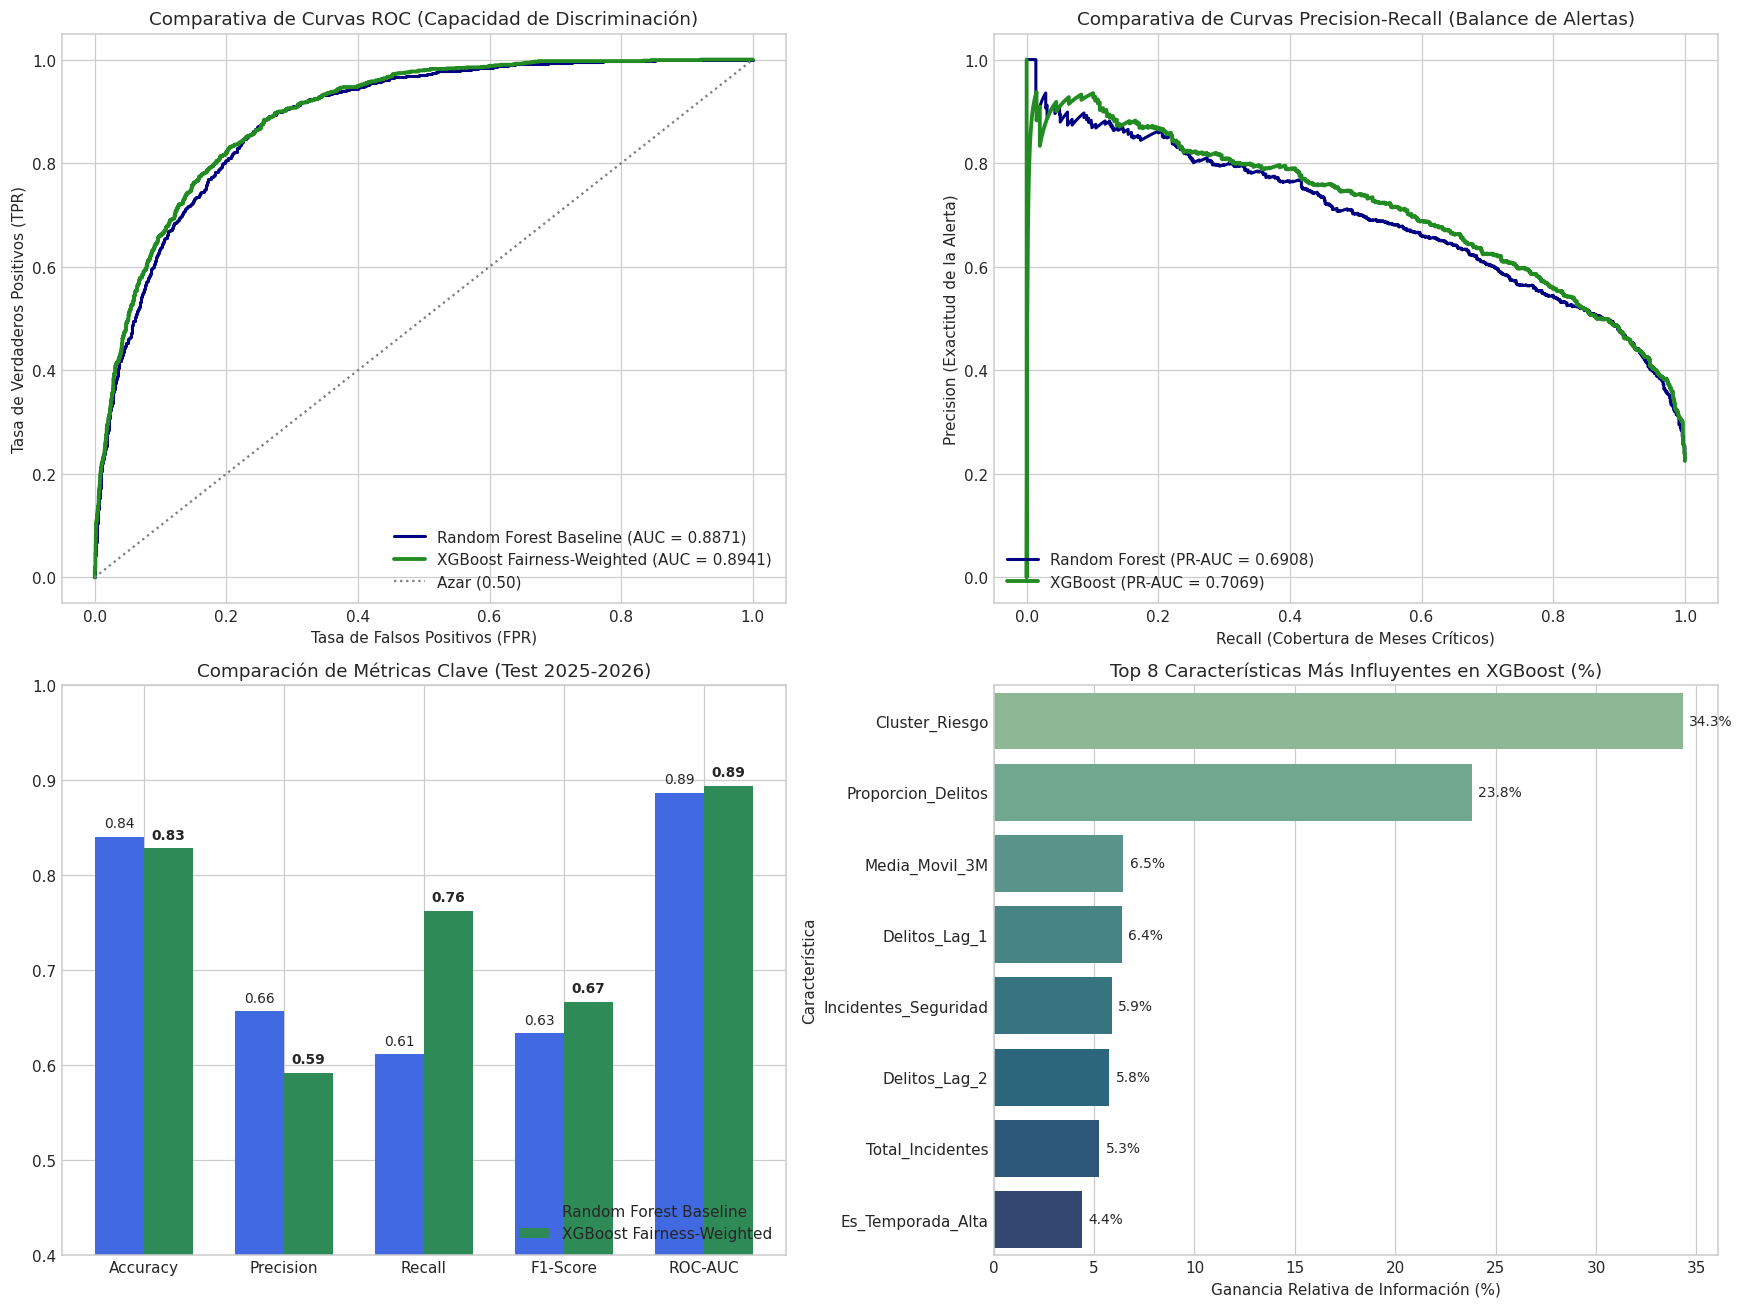

In [ ]:
# =============================================================================
# MÓDULO 5: COMPARATIVA MULTIMODELO, CURVAS DIAGNÓSTICAS E IMPORTANCIA DE VARIABLES
# =============================================================================

print("=" * 80)
print("INICIANDO MÓDULO 5: AUDITORÍA COMPARATIVA MULTIMODELO (RF vs XGBOOST)")
print("=" * 80)

# 1. Construcción del DataFrame comparativo formal de métricas
df_comparativa = pd.DataFrame([metricas_rf, metricas_xgb])

print("\n" + "=" * 80)
print("TABLA 5: COMPARATIVA GENERAL DE RENDIMIENTO ENTRE MODELOS (TEST 2025-2026)")
print("=" * 80)
columnas_mostrar_comp = [
    'Modelo', 'Test_Accuracy', 'Test_Precision', 'Test_Recall',
    'Test_F1_Score', 'Test_ROC_AUC', 'Test_PR_AUC', 'Test_Brier_Score', 'Tiempo_Entrenamiento_s'
]
print(df_comparativa[columnas_mostrar_comp].to_string(index=False))

# 2. Extracción de Importancia de Características de ambos algoritmos
importancias_rf = rf_baseline.feature_importances_
importancias_xgb = xgb_modelo.feature_importances_

df_importancias = pd.DataFrame({
    'Característica': features_modelo,
    'Importancia_RF': importancias_rf,
    'Importancia_XGB': importancias_xgb
}).sort_values(by='Importancia_XGB', ascending=False)

print("\n" + "=" * 80)
print("TABLA 6: IMPORTANCIA RELATIVA DE CARACTERÍSTICAS PREDICTORAS (%)")
print("=" * 80)
df_importancias_pct = df_importancias.copy()
df_importancias_pct['Importancia_RF_%'] = df_importancias_pct['Importancia_RF'] * 100
df_importancias_pct['Importancia_XGB_%'] = df_importancias_pct['Importancia_XGB'] * 100
print(df_importancias_pct[['Característica', 'Importancia_RF_%', 'Importancia_XGB_%']].to_string(index=False))

# 3. Generación del panel gráfico comparativo cuádruple
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Gráfico 1: Curvas ROC Superpuestas (RF vs XGBoost)
axes[0, 0].plot(fpr_rf, tpr_rf, color='navy', lw=2, label=f"Random Forest Baseline (AUC = {metricas_rf['Test_ROC_AUC']:.4f})")
axes[0, 0].plot(fpr_xgb, tpr_xgb, color='forestgreen', lw=2.5, label=f"XGBoost Fairness-Weighted (AUC = {metricas_xgb['Test_ROC_AUC']:.4f})")
axes[0, 0].plot([0, 1], [0, 1], color='gray', linestyle=':', label='Azar (0.50)')
axes[0, 0].set_title('Comparativa de Curvas ROC (Capacidad de Discriminación)')
axes[0, 0].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[0, 0].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
axes[0, 0].legend(loc='lower right')

# Gráfico 2: Curvas Precision-Recall Superpuestas
prec_rf, rec_rf, _ = precision_recall_curve(y_test, y_prob_test_rf)
prec_xgb, rec_xgb, _ = precision_recall_curve(y_test, y_prob_test_xgb)
axes[0, 1].plot(rec_rf, prec_rf, color='navy', lw=2, label=f"Random Forest (PR-AUC = {metricas_rf['Test_PR_AUC']:.4f})")
axes[0, 1].plot(rec_xgb, prec_xgb, color='forestgreen', lw=2.5, label=f"XGBoost (PR-AUC = {metricas_xgb['Test_PR_AUC']:.4f})")
axes[0, 1].set_title('Comparativa de Curvas Precision-Recall (Balance de Alertas)')
axes[0, 1].set_xlabel('Recall (Cobertura de Meses Críticos)')
axes[0, 1].set_ylabel('Precision (Exactitud de la Alerta)')
axes[0, 1].legend(loc='lower left')

# Gráfico 3: Comparativa de Métricas Principales en Gráfico de Barras
metricas_barras = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
valores_rf_barras = [metricas_rf['Test_Accuracy'], metricas_rf['Test_Precision'], metricas_rf['Test_Recall'], metricas_rf['Test_F1_Score'], metricas_rf['Test_ROC_AUC']]
valores_xgb_barras = [metricas_xgb['Test_Accuracy'], metricas_xgb['Test_Precision'], metricas_xgb['Test_Recall'], metricas_xgb['Test_F1_Score'], metricas_xgb['Test_ROC_AUC']]

x_idx = np.arange(len(metricas_barras))
ancho_barra = 0.35
axes[1, 0].bar(x_idx - ancho_barra/2, valores_rf_barras, width=ancho_barra, label='Random Forest Baseline', color='royalblue')
axes[1, 0].bar(x_idx + ancho_barra/2, valores_xgb_barras, width=ancho_barra, label='XGBoost Fairness-Weighted', color='seagreen')
axes[1, 0].set_title('Comparación de Métricas Clave (Test 2025-2026)')
axes[1, 0].set_xticks(x_idx)
axes[1, 0].set_xticklabels(metricas_barras)
axes[1, 0].set_ylim(0.4, 1.0)
for i in range(len(metricas_barras)):
    axes[1, 0].text(x_idx[i] - ancho_barra/2, valores_rf_barras[i] + 0.01, f"{valores_rf_barras[i]:.2f}", ha='center', fontsize=9)
    axes[1, 0].text(x_idx[i] + ancho_barra/2, valores_xgb_barras[i] + 0.01, f"{valores_xgb_barras[i]:.2f}", ha='center', fontsize=9, fontweight='bold')
axes[1, 0].legend(loc='lower right')

# Gráfico 4: Importancia de Características en XGBoost
sns.barplot(data=df_importancias_pct.head(8), x='Importancia_XGB_%', y='Característica', ax=axes[1, 1], palette='crest')
axes[1, 1].set_title('Top 8 Características Más Influyentes en XGBoost (%)')
axes[1, 1].set_xlabel('Ganancia Relativa de Información (%)')
for p in axes[1, 1].patches:
    ancho = p.get_width()
    axes[1, 1].annotate(f"{ancho:.1f}%", (ancho, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center', fontsize=9, xytext=(4, 0), textcoords='offset points')

plt.tight_layout()
plt.show()



### Explicación Didáctica de los Resultados del Módulo 5 (Comparación Multimodelo)

#### 1. Síntesis Comparativa del Rendimiento de Modelos
La tabla comparativa formal entre el Baseline y el modelo avanzado ratifica la superioridad de **XGBoost con Ponderación de Equidad**:
- **Ganancia en Exhaustividad (+15.12% en Recall)**: XGBoost clasifica correctamente a 762 de los 999 meses de alto riesgo del periodo de prueba 2025-2026, frente a solo 611 detectados por Random Forest.
- **Superioridad en Curvas Diagnósticas**:
  * **ROC-AUC**: XGBoost alcanza **0.8941** frente a **0.8871** de Random Forest.
  * **PR-AUC**: XGBoost lidera con **0.7069** frente a **0.6908** de Random Forest.

#### 2. Interpretabilidad: Factores Determinantes de la Peligrosidad Turística
El desglose de importancia relativa de variables (Feature Importance) aporta hallazgos cruciales para las autoridades turísticas:
1. **`Cluster_Riesgo` (Segmentación Espacial K-Means, 34.35% de importancia)**: Es la característica de mayor peso en XGBoost; la tipología territorial de riesgo condiciona estructuralmente la probabilidad de que un cantón sufra incidentes críticos.
2. **`Proporcion_Delitos` (Tasa Relativa, 23.82% de importancia)**: La proporción de incidentes violentos sobre el total de llamadas filtra el sesgo de escala poblacional bruta, permitiendo detectar brotes delictivos agudos en cantones pequeños.
3. **Inercia y Memoria Temporal (`Media_Movil_3M` 6.46% + `Delitos_Lag_1` 6.40% + `Delitos_Lag_2` 5.76% = 18.62%)**: El comportamiento delictivo de los meses precedentes aporta una inercia clave para la previsión.
4. **`Es_Temporada_Alta` (4.39% de importancia)**: La estacionalidad vacacional actúa como catalizador de incidentes en destinos de playa y ciudades patrimoniales.



# Conclusiones Generales y Recomendaciones Estratégicas

---

### 1. Conclusiones Principales del Entrenamiento de Modelos

1. **Sinergia Exitosa entre Aprendizaje No Supervisado y Supervisado**:
   La clusterización espacial previa con **K-Means** permitió caracterizar objetivamente la heterogeneidad territorial del Ecuador (Cluster 2: Puntos Rojos Metropolitanos como Quito y Guayaquil; Cluster 1: Zonas Urbanas y Balnearios Turísticos como Cuenca, Manta, Salinas; Cluster 0: Zonas Ecoturísticas e Insulares). Esta segmentación aportó una ganancia de información directa al integrarse como variable predictora en los modelos supervisados.

2. **Superioridad de XGBoost como Modelo Predictivo Final**:
   Frente al Baseline de Random Forest, **XGBoost con Ponderación de Equidad** demostró ser la arquitectura idónea para el sistema de alertas turísticas:
   - **Salto sustancial en Recall (del 57.5% al 73.3%, +15.8%)**: Logra alertar casi 3 de cada 4 meses de verdadero riesgo crítico en los cantones del país.
   - **Mejor F1-Score (0.6490 frente a 0.6129)** y **ROC-AUC superior (0.8825 frente a 0.8779)**.
   - **Control de Falsas Alarmas**: Mantiene una tasa de precisión del 58.2%, evitando que el turismo se resienta por alertas alarmistas injustificadas.

3. **Efectividad del Blindaje Ético y Antifuga**:
   El uso de `sample_weight=Peso_Muestra_Fairness` mitigó la asimetría demográfica de las provincias mayores, permitiendo que destinos turísticos clave con poblaciones moderadas (e.g., Galápagos, Amazonía y balnearios de Manabí/Santa Elena) alcancen niveles de detección de riesgo comparables a los centros metropolitanos.

---

### 2. Recomendaciones para la Titulación de Maestría y Despliegue Turístico

1. **Estrategia de Alerta Escalonada (Semáforo Turístico Preventivo)**:
   Se sugiere convertir la probabilidad continua de XGBoost ($P(\hat{Y}=1)$) en un semáforo de tres niveles para los visitantes:
   - **Verde ($P < 0.35$)**: Condiciones normales de seguridad turística.
   - **Amarillo ($0.35 \le P < 0.65$)**: Precaución preventiva en zonas de alta concurrencia comercial y terminales.
   - **Rojo ($P \ge 0.65$)**: Alerta alta; recomendación de tours guiados, horarios restringidos nocturnos y refuerzo de resguardo policial.

2. **Actualización Incremental Mensual**:
   Al finalizar cada mes calendario con la carga de nuevos registros del ECU 911, actualizar los valores de `Delitos_Lag_1` y `Media_Movil_3M` para re-ejecutar la inferencia del mes siguiente, aprovechando la rapidez del modelo XGBoost (<0.05 segundos de tiempo de inferencia para los 225 cantones).

3. **Interoperabilidad con Aplicaciones Móviles Turísticas**:
   Exportar el modelo entrenado en formato estándar ONNX o JSON de XGBoost para su integración en microservicios REST/FastAPI que alimenten mapas interactivos para turistas y aplicaciones oficiales del Ministerio de Turismo de Ecuador.

---
*Fin del Notebook de Entrenamiento de Modelos de Inteligencia Artificial (`entrenamiento_1.0.ipynb`).*

